# 02 · Error analysis: `ablation_effnet_b0`

Inputs come from `python -m src.evaluate` (`results/ablation_effnet_b0/`). Goal: understand *which* dishes fail, *why*, and *what a mistake costs* in calories.

In [1]:
import os, sys, json
sys.path.insert(0, os.path.abspath('..'))
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from PIL import Image
ROOT = os.path.abspath('..'); EXP = 'ablation_effnet_b0'
R = f'{ROOT}/results/{EXP}'
IMG_ROOT = f'{ROOT}/data/cache/food101_256'
metrics = json.load(open(f'{R}/metrics.json')); metrics

{'experiment': 'ablation_effnet_b0',
 'backbone': 'efficientnet_b0',
 'split': 'test',
 'num_images': 3000,
 'num_classes': 20,
 'top1': 0.91,
 'top5': 0.9876666666666667,
 'macro_f1': 0.9101990476375624,
 'params_m': 4.03,
 'cpu_latency_ms': 24.9}

## Per-class F1: hardest and easiest dishes

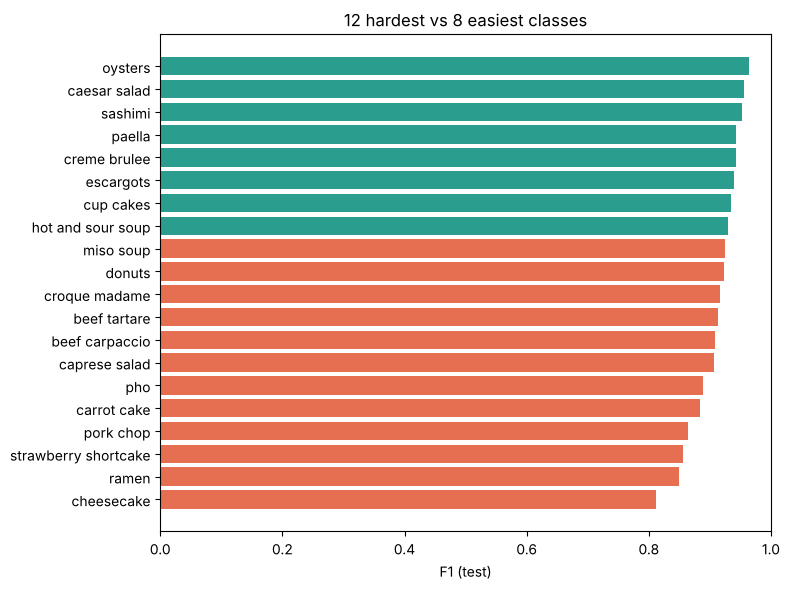

,class,precision,recall,f1,support
0,cheesecake,0.8322,0.7933,0.8123,150
1,ramen,0.8732,0.8267,0.8493,150
2,strawberry_shortcake,0.8591,0.8533,0.8562,150
3,pork_chop,0.8081,0.9267,0.8634,150
4,carrot_cake,0.8758,0.8933,0.8845,150
5,pho,0.8528,0.9267,0.8882,150
6,caprese_salad,0.8805,0.9333,0.9061,150
7,beef_carpaccio,0.9184,0.9000,0.9091,150
8,beef_tartare,0.9079,0.9200,0.9139,150
9,croque_madame,0.9252,0.9067,0.9158,150


In [2]:
pc = pd.read_csv(f'{R}/per_class.csv').sort_values('f1')
show = pd.concat([pc.head(12), pc.tail(8)])
plt.figure(figsize=(8, 6))
plt.barh(show['class'].str.replace('_',' '), show.f1, color=['#e76f51']*12 + ['#2a9d8f']*8)
plt.xlabel('F1 (test)'); plt.title('12 hardest vs 8 easiest classes'); plt.xlim(0, 1); plt.tight_layout()
plt.savefig(f'{ROOT}/assets/per_class_f1.png', dpi=100); plt.show()
pc.head(12)

## Most-confused pairs (true → predicted)

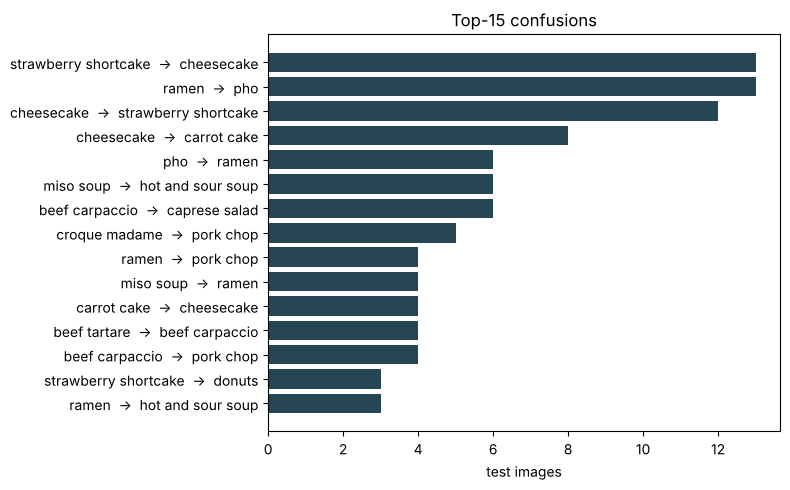

,true,predicted,count,rate_of_true_class
0,strawberry_shortcake,cheesecake,13,0.087
1,ramen,pho,13,0.087
2,cheesecake,strawberry_shortcake,12,0.080
3,cheesecake,carrot_cake,8,0.053
4,pho,ramen,6,0.040
5,miso_soup,hot_and_sour_soup,6,0.040
6,beef_carpaccio,caprese_salad,6,0.040
7,croque_madame,pork_chop,5,0.033
8,ramen,pork_chop,4,0.027
9,miso_soup,ramen,4,0.027


In [3]:
cp = pd.read_csv(f'{R}/confused_pairs.csv').head(15)
lab = cp.true.str.replace('_',' ') + '  →  ' + cp.predicted.str.replace('_',' ')
plt.figure(figsize=(8, 5)); plt.barh(lab[::-1], cp['count'][::-1], color='#264653')
plt.xlabel('test images'); plt.title('Top-15 confusions'); plt.tight_layout()
plt.savefig(f'{ROOT}/assets/confused_pairs.png', dpi=100); plt.show()
cp

## Confidence: is the model's confidence meaningful?
The app warns when top-1 confidence < 0.4. This checks that low confidence really does flag likely errors, and how much a user-correction step recovers (true label inside the top-3 shown to the user).

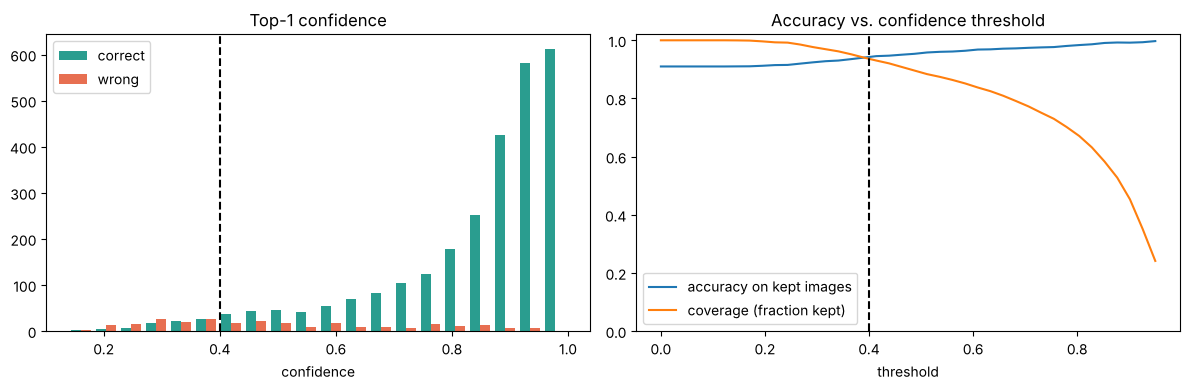

top-1 0.910 | top-3 0.977
images flagged low-confidence: 6.3%; accuracy flagged 0.429 vs not flagged 0.942
errors recoverable by picking from the top-3 list: 74.1%


In [4]:
pr = pd.read_csv(f'{R}/predictions.csv')
pr['top3'] = pr.top5.str.split('|').apply(lambda xs: [x.split(':')[0] for x in xs[:3]])
pr['in_top3'] = [t in s for t, s in zip(pr.true, pr.top3)]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist([pr.conf[pr.correct == 1], pr.conf[pr.correct == 0]], bins=20, label=['correct', 'wrong'], color=['#2a9d8f', '#e76f51'])
ax[0].axvline(0.4, ls='--', c='k'); ax[0].set(title='Top-1 confidence', xlabel='confidence'); ax[0].legend()
th = np.linspace(0, 0.95, 40)
ax[1].plot(th, [pr.correct[pr.conf >= t].mean() for t in th], label='accuracy on kept images')
ax[1].plot(th, [(pr.conf >= t).mean() for t in th], label='coverage (fraction kept)')
ax[1].axvline(0.4, ls='--', c='k'); ax[1].set(title='Accuracy vs. confidence threshold', xlabel='threshold', ylim=(0, 1.02)); ax[1].legend()
plt.tight_layout(); plt.savefig(f'{ROOT}/assets/confidence.png', dpi=100); plt.show()
low = pr.conf < 0.4
print(f"top-1 {pr.correct.mean():.3f} | top-3 {pr.in_top3.mean():.3f}")
print(f"images flagged low-confidence: {low.mean():.1%}; accuracy flagged {pr.correct[low].mean():.3f} vs not flagged {pr.correct[~low].mean():.3f}")
print(f"errors recoverable by picking from the top-3 list: {pr.in_top3[pr.correct == 0].mean():.1%}")

## What does a mistake cost in calories?
For every misclassified image: |kcal(predicted dish) − kcal(true dish)| for one typical serving of the true dish's weight. Confusing two similar cakes is cheap; confusing a salad with a cake is not.

In [5]:
from src.nutrition import load_db
db = load_db()
err = pr[pr.correct == 0].copy()
err['kcal_true'] = [db.estimate(t, db.get(t).serving_g).kcal for t in err.true]
err['kcal_pred'] = [db.estimate(p, db.get(t).serving_g).kcal for p, t in zip(err.pred, err.true)]
err['abs_err'] = (err.kcal_pred - err.kcal_true).abs()
err['rel_err'] = err.abs_err / err.kcal_true
print(err[['abs_err', 'rel_err']].describe(percentiles=[.5, .9]).round(2))
print(f"\nmisclassifications costing <20% kcal error: {(err.rel_err < 0.2).mean():.1%}")
worst = err.groupby(['true', 'pred']).agg(n=('abs_err', 'size'), kcal_err=('abs_err', 'mean')).query('n >= 2').sort_values('kcal_err', ascending=False).head(10)
worst.round(0)

       abs_err  rel_err
count   270.00   270.00
mean    169.46     0.66
std     148.27     0.83
min       3.40     0.01
50%     122.50     0.44
90%     368.21     1.46
max     727.60     5.19

misclassifications costing <20% kcal error: 27.0%


n  kcal_err
true                 pred                              
cheesecake           creme_brulee           2     500.0
creme_brulee         donuts                 2     407.0
carrot_cake          pork_chop              2     382.0
cheesecake           pork_chop              2     378.0
strawberry_shortcake donuts                 3     371.0
                     cheesecake            13     324.0
cheesecake           strawberry_shortcake  12     324.0
carrot_cake          beef_tartare           2     294.0
miso_soup            ramen                  4     252.0
ramen                miso_soup              2     252.0

## Failure gallery: the most confident mistakes
Each pair: the photo with Grad-CAM for the **wrong** predicted class, then Grad-CAM for the **true** class.

/home/user/calories-/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


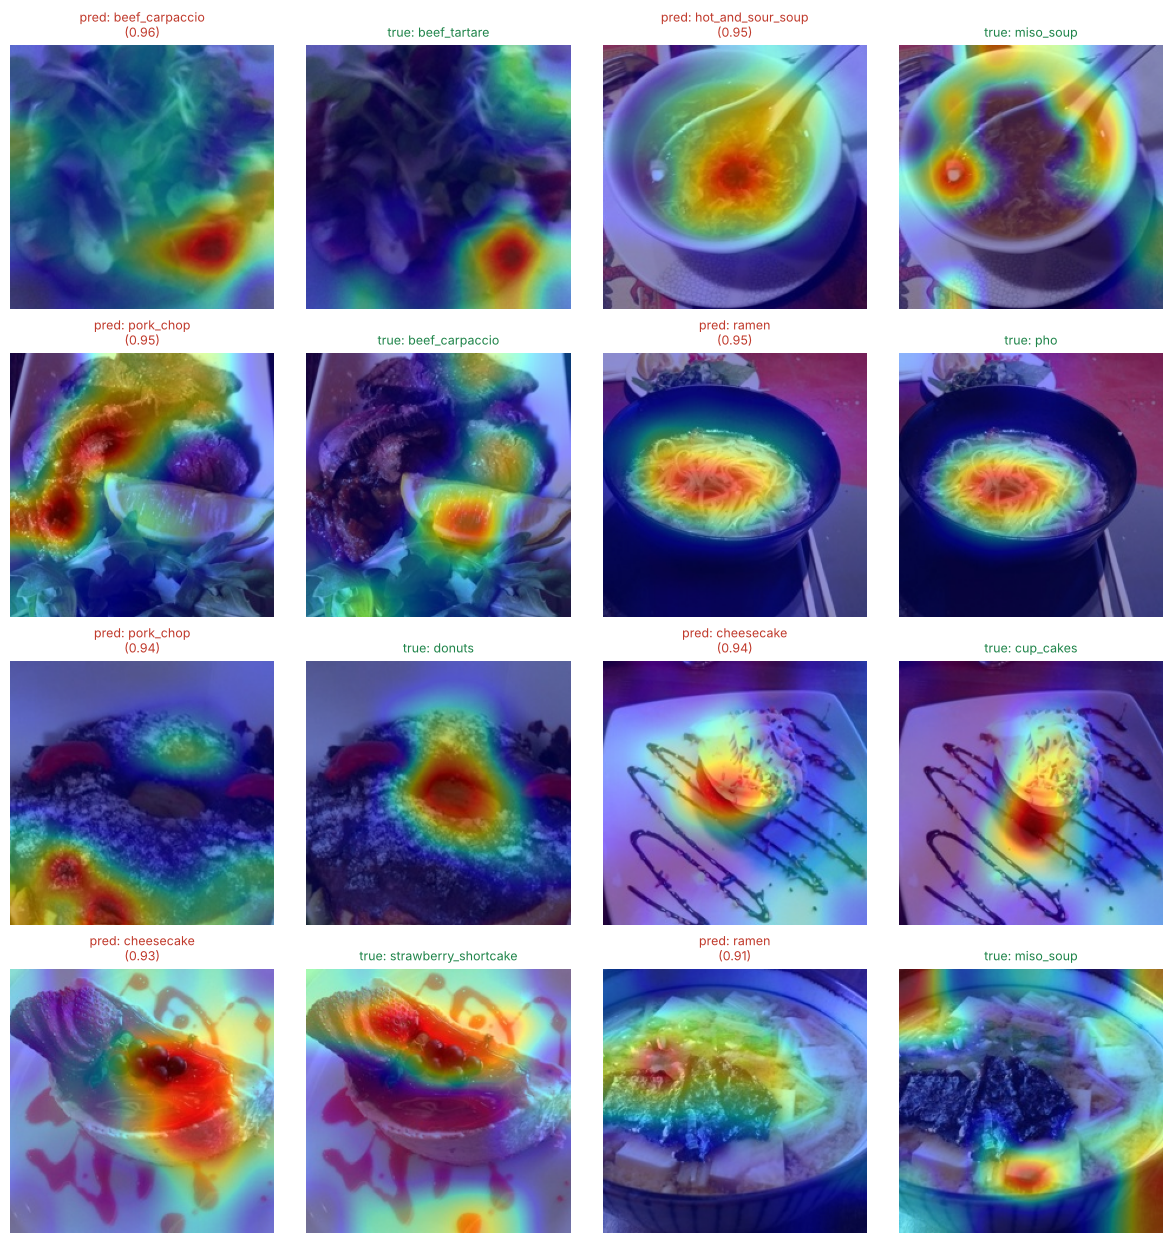

In [6]:
from src.predict import Predictor
ckpt = f'{ROOT}/checkpoints/{EXP}/best.pt'
P = Predictor(ckpt, tta=False)
wrong = pr[pr.correct == 0].sort_values('conf', ascending=False).head(8)
fig, axes = plt.subplots(4, 4, figsize=(12, 12.5))
for (_, r), ax2 in zip(wrong.iterrows(), axes.reshape(-1, 2)):
    img = Image.open(f'{IMG_ROOT}/{r.path}').convert('RGB')
    ax2[0].imshow(P.explain(img, r.pred)); ax2[0].set_title(f'pred: {r.pred}\n({r.conf:.2f})', fontsize=9, color='#c0392b')
    ax2[1].imshow(P.explain(img, r.true)); ax2[1].set_title(f'true: {r.true}', fontsize=9, color='#1e8449')
    for a in ax2: a.axis('off')
plt.tight_layout(); plt.savefig(f'{ROOT}/assets/failure_cases.jpg', dpi=80); plt.show()

## Notes: why these fail

Observations from this run (EfficientNet-B0, 20-class subset, 3,000 test images; re-run on the full model with `python run_all.py`):

1. **Fine-grained siblings dominate the errors.** The top confusions are within one visual family:
   *soups* (ramen ↔ pho, miso ↔ hot-and-sour), *cakes* (cheesecake ↔ strawberry shortcake ↔ carrot cake)
   and *raw-meat starters* (beef carpaccio ↔ beef tartare ↔ caprese). At 224 px, a bowl of broth with
   noodles is mostly the same texture; the distinguishing cues (broth clarity, herbs, the cut of the meat,
   a strawberry layer) occupy a few pixels.
2. **Some "errors" are label noise or genuinely ambiguous images.** In the failure gallery the *pho* bowl is
   visually indistinguishable from ramen (the Grad-CAMs for both classes are identical), and the *cup_cakes*
   example is a plated slice of cake with chocolate drizzle. Food-101's authors deliberately left noise in the
   images, so part of the residual error is irreducible.
3. **Shortcut / context cues.** In several confident mistakes the heatmap sits on a **garnish, lemon wedge or
   plate decoration** rather than the food (e.g. carpaccio → pork chop focuses on a grilled-looking edge and
   the lemon). The model learned co-occurring context; it fails when the context is misleading.
4. **Lighting.** Dark or coloured restaurant lighting (purple/blue casts) removes the colour cues that separate
   raw beef from cooked pork or a red-velvet crumb from chocolate.

**What this means for the product**
- **Confidence is informative:** the 6% of images below the 0.4 threshold are only 43% accurate (vs 94% above it),
  so the app's low-confidence warning targets the right images.
- **The top-3 list is worth showing:** 74% of all errors have the true dish in the top-3, so a single tap fixes
  most mistakes (top-3 accuracy 97.7%).
- **But errors are expensive in calories:** only 27% of misclassifications are within 20% of the true kcal.
  Confusing a strawberry shortcake (214 kcal/100 g) with a cheesecake (399 kcal/100 g) costs ~320 kcal per serving.
  The typical error is ~120 kcal (median). This is why the correction UI matters more than a further 1–2% of accuracy.

**Next steps suggested by the analysis:** higher input resolution (288–320 px) for fine-grained cues, a
hierarchical "family then dish" head, temperature scaling so the warning threshold maps to a known error rate,
and hard-example mining on the sibling pairs above.
